# Gear-mesh benchmark: ValDyn → Python, and how to calibrate it

This notebook rebuilds the two ValDyn benchmark models from *Benchmark-Daten-Kalibrierung.key* in Python and calibrates them against the ValDyn results, which are only available as screen photos.

| | Stage 1: gear pair (GEARMESH2D) | Stage 2: gear on shaft with bearing and non-linear supports |
|---|---|---|
| Model | 6 DOF: 2 gears (x, y, θ) | 12 DOF: gear 1 (x, y, θ), gear 2 (x, y, θ), shaft with 3 nodes (x, y) |
| Excitation | 2500 rpm through a torsional spring, 10 N·m drag torque step | 10·sin(θ) N·m angle-dependent load |
| Result with the **exact** ValDyn parameters | already matches closely | does **not** match (lash about 10× too large) |
| Calibration result | small refinement only (k_mesh ≈ −8 %, within data uncertainty) | backlash about **0.012 mm** (mask: 0.25), mesh stiffness about **25 000 N/mm** (mask: 308 000) |

The notebook also teaches the method. Each calibration step is labelled **[Mx]** and refers back to the procedure in **Part C**.

**Files** (all in this folder):
`gearmesh_model.py` (models) · `calib_tools.py` (metrics, sensitivity, screening, optimisation helpers) · `stage2_objective.py` · `digitize_valdyn_plots.py` (rebuilds the reference data from the .key) · `reference_valdyn_digitized.npz` (digitised ValDyn curves)

**Requirements:** `numpy scipy matplotlib numba`. The model also runs without numba, but stage 2 is then about 100× slower. Running the whole notebook takes about 10–15 min, and stage 2 accounts for most of that.

In [1]:
import time, json, numpy as np, matplotlib.pyplot as plt
from scipy.optimize import minimize
import gearmesh_model as gm, calib_tools as ct, stage2_objective as so
plt.rcParams.update({'figure.dpi': 90, 'axes.grid': True, 'font.size': 9})
print('numba available:', gm.HAVE_NUMBA)
REF = ct.load_reference('reference_valdyn_digitized.npz')
t0 = time.time(); gm.simulate_stage1(); gm.simulate_stage2(angle_end=10)   # JIT compile
print(f'compiled in {time.time()-t0:.1f} s')

numba available: True


compiled in 0.2 s


# Part A: reference data

## A.1 Parameters (transcribed 1:1 from the ValDyn masks in the photos)

| Element | Parameter | Value | Source slide |
|---|---|---|---|
| Excitation | speed | 2500 rpm (stage 2 results are labelled **03000**) | "Antrieb", "Modell" |
| Drive spring | k / c | 4.3e7 N·m/rad / 172 N·m·s/rad | "Antrieb" |
| Gear 1 (BUSH_1) | m_x = m_y / J | 2.67 kg / 0.01709 kg·m² | "Masse 1" |
| Gear 1 supports | k / c (x and y) | 3.6e9 N/m / 10218 N·s/m | "Masse 1" |
| Gear 2 (BUSH_2) | m / J / centre | 1.5 kg / 0.0054 kg·m² / (131.56, 47.88) mm | "Masse 2" |
| Gear 2 supports (stage 1) | k / c | 3.6e9 N/m / 7397 N·s/m | "Masse 2" |
| Gear 2 initial speed | | −1.37 deg/deg (40/30 would be −1.333) | "Masse 2" |
| Drag torque | preload | 10 N·m (k = c = 0) | "Masse 2" |
| GEARMESH2D_1 | k / c | 308 000 N/mm / 4300 N·s/m | "2D Zahnradpaar" |
| | z_i / z_j / a / α | 40 / 30 / 140 mm / 20° | |
| | initial **normal** backlash | 0.25 mm | |
| Shaft 4/5 | Ø26/Ø20 mm, 2 × 50 mm, E = 210 000 N/mm², ρ = 7.85e-6 kg/mm³ | | "Modellergänzung" |
| Shaft nodes | MASS_8 = ρ(dAo²−dAi²)·lA1 (**no** /2·π/4, unlike MASS_9!) | 0.108 / 0.085 / 0.043 kg | |
| R_BEARING_1 | radial k / c / clearance | 500 000 N/mm / 1.26 N·s/m / 30 µm | |
| | friction coefficient / diameter | 0.001 / 28 mm | |
| Block/Case supports | tables BlockX/Y, CaseX/Y | ±2 µm soft zone (5000 N/mm), then 2e5 (Block) or 1e5 (Case) N/mm | `NonlinearStiffnesses/*.rtf` |
| Stage 2 load | SINUS10.txt | 10·sin(θ) N·m, period 360° of the driver angle | |

Inconsistencies are marked in bold. They are candidate causes of mismatch and are tested as hypotheses below.

BlockX  file not found, using built-in table
BlockY  file not found, using built-in table
CaseX   file not found, using built-in table
CaseY   file not found, using built-in table


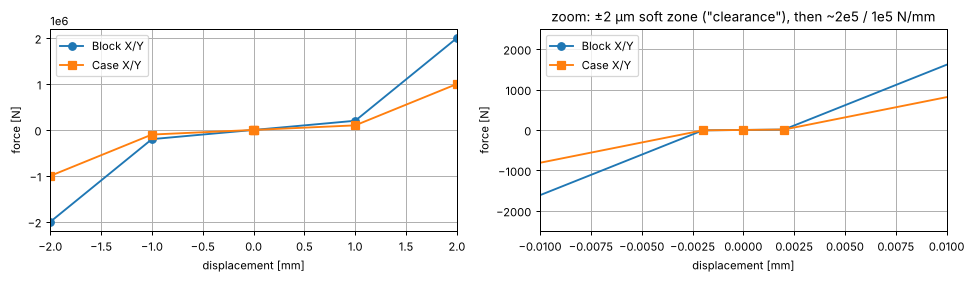

In [2]:
# the non-linear support tables are read directly from your .rtf files (fallback: built-in copy)
import os
p2 = gm.params(2)
for key, fn in [('block_x', 'BlockX'), ('block_y', 'BlockY'), ('case_x', 'CaseX'), ('case_y', 'CaseY')]:
    path = os.path.join('..', 'NonlinearStiffnesses', fn + '.rtf')
    if os.path.exists(path):
        tab = gm.read_valdyn_table(path)
        assert np.allclose(tab, p2[key]), f'{fn} differs from built-in table'
        print(f'{fn:7s} read from file, {len(tab)} rows  ->  identical to built-in table')
    else:
        print(f'{fn:7s} file not found, using built-in table')
tab = np.array(p2['block_x']); tc = np.array(p2['case_x'])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for a, lim in zip(ax, [2, 0.01]):
    a.plot(tab[:, 0], tab[:, 1], 'o-', label='Block X/Y'); a.plot(tc[:, 0], tc[:, 1], 's-', label='Case X/Y')
    a.set_xlim(-lim, lim); a.set_xlabel('displacement [mm]'); a.set_ylabel('force [N]'); a.legend()
    if lim < 1: a.set_ylim(-2500, 2500)
ax[1].set_title('zoom: ±2 µm soft zone ("clearance"), then ~2e5 / 1e5 N/mm'); plt.tight_layout()

## A.2 Turning photographed plots into data (`digitize_valdyn_plots.py`)

The ValDyn results exist only as photos of a screen, taken at an angle. Each plot is processed in five steps:

1. Pick the four plot-frame corners roughly by hand.
2. **Refine** each frame edge automatically: search for the darkest line nearby and fit straight lines. This gives sub-pixel corners.
3. Compute a **homography** (perspective transform) that maps photo pixels to data coordinates, with the axis limits taken from the tick labels.
4. Use a **colour mask** (red, green, blue or cyan line) to get a point cloud of the curve.
5. De-duplicate the points on a grid.

Every later comparison therefore works against **point clouds**, not time series. Three consequences:
* The metric must not need matching time stamps. Part C uses a *Chamfer distance* for this.
* The digitised data have a **noise floor** from line thickness, photo blur and two overlaid traces in the force plots. An error below that floor carries no information. The cell after the next estimates it for the smooth curves: about **0.6–1 %** of the plot size.
* A curve lying under the black zero axis is invisible. The metric therefore ignores simulated points that sit on the zero axis (`hide_y0`).

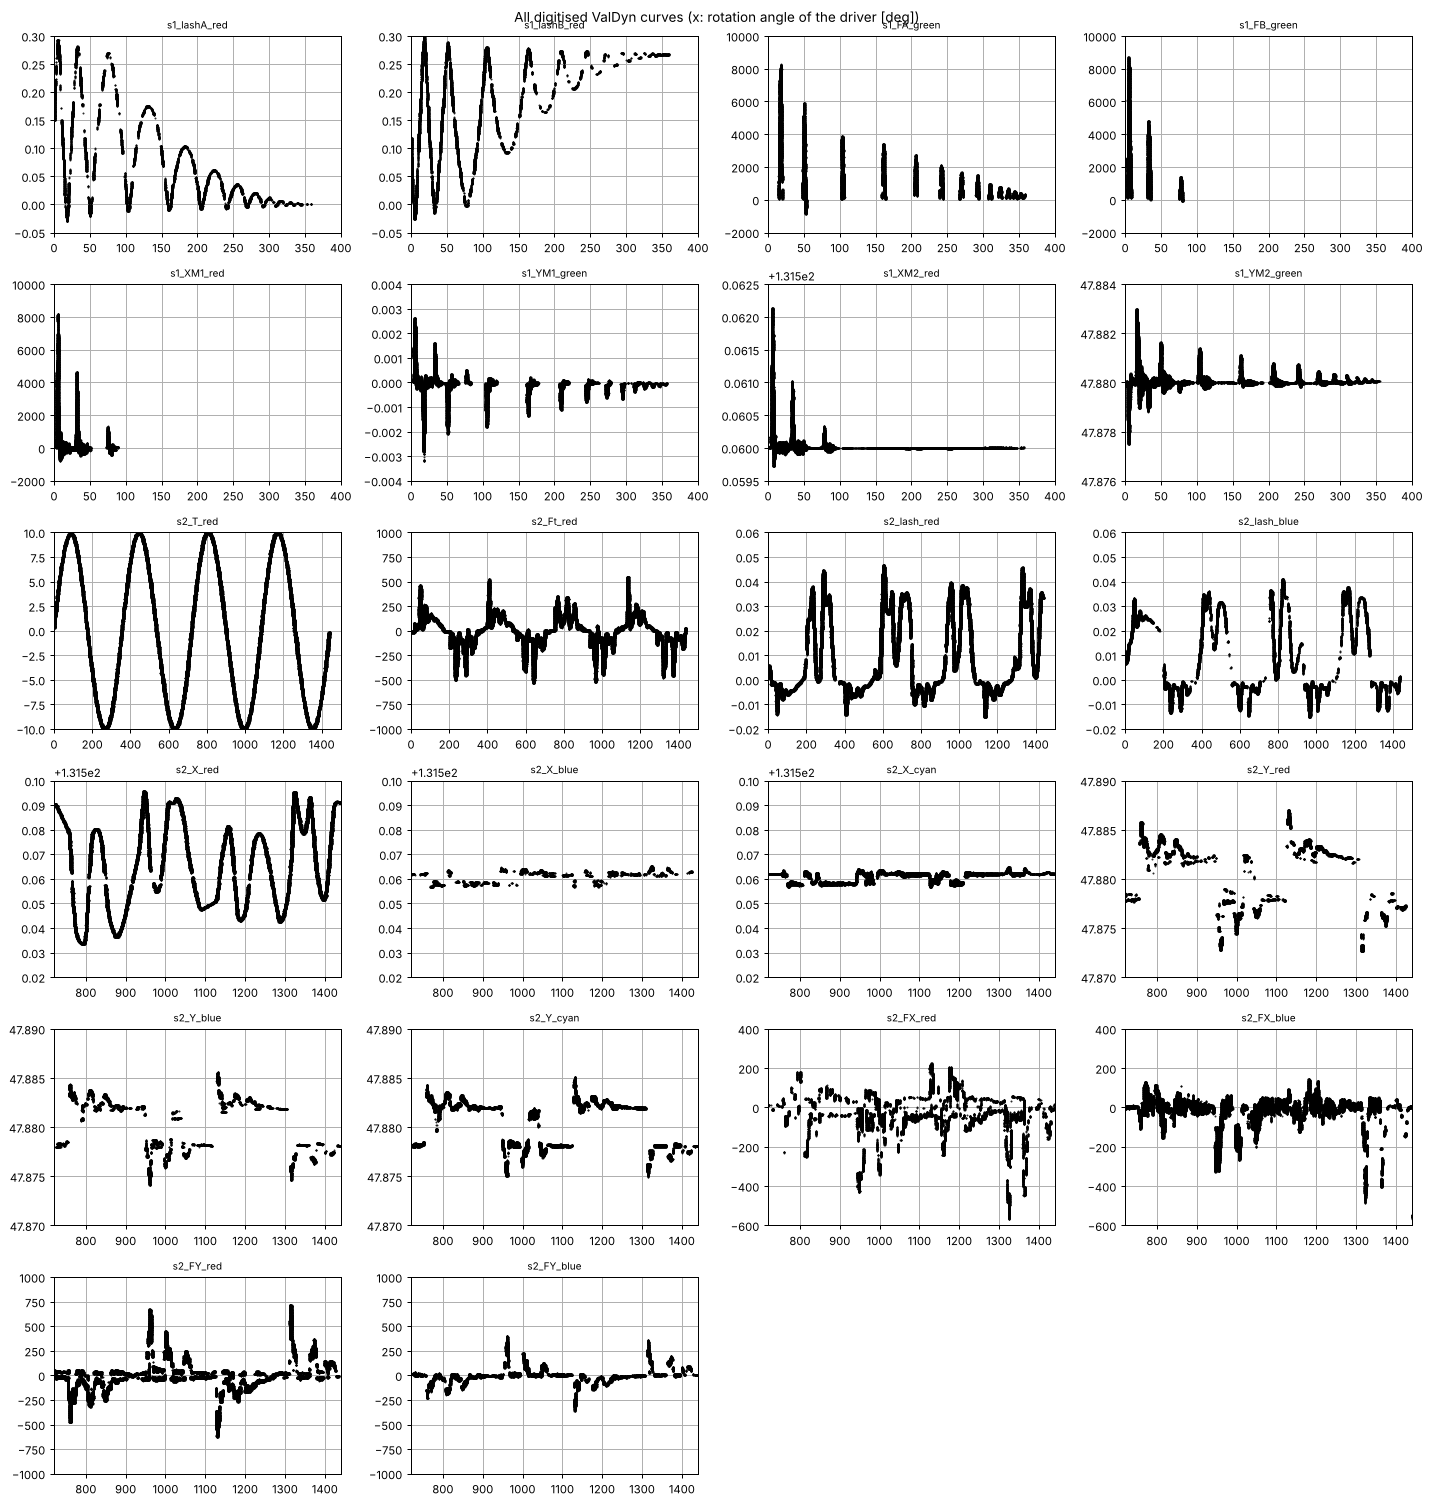

In [3]:
keys = [k for k in REF]
fig, axs = plt.subplots(6, 4, figsize=(16, 17)); axs = axs.ravel()
for ax, k in zip(axs, keys):
    R = REF[k]; ax.plot(R.pts[:, 0], R.pts[:, 1], '.', ms=1, color='k')
    ax.set_xlim(R.xr); ax.set_ylim(R.yr); ax.set_title(k, fontsize=8)
for ax in axs[len(keys):]: ax.axis('off')
plt.suptitle('All digitised ValDyn curves (x: rotation angle of the driver [deg])'); plt.tight_layout()

In [4]:
# Noise floor of the digitised data: distance of each point cloud to its own column-median curve.
# A model error close to these numbers cannot be improved in a meaningful way.
def noise_floor(R, n=800):
    P = R.pts; e = np.linspace(R.xr[0], R.xr[1], n+1); xc = 0.5*(e[1:]+e[:-1])
    idx = np.digitize(P[:, 0], e)-1
    med = np.array([np.median(P[idx == i, 1]) if np.sum(idx == i) > 2 else np.nan for i in range(n)])
    m = np.isfinite(med)
    return ct.curve_distance(R, xc[m], med[m], mode='ref')
# only meaningful for smooth curves; for spiky force plots the column median misses the vertical strokes
smooth = ['s1_lashA_red', 's1_lashB_red', 's2_T_red', 's2_X_red', 's2_Y_cyan']
floor = {k: noise_floor(REF[k]) for k in smooth}
print('digitisation floor (RMS distance, fraction of plot size):', {k: round(v, 4) for k, v in floor.items()})

digitisation floor (RMS distance, fraction of plot size): {'s1_lashA_red': 0.0079, 's1_lashB_red': 0.0099, 's2_T_red': 0.0056, 's2_X_red': 0.0069, 's2_Y_cyan': 0.0057}


# Part B: the model (`gearmesh_model.py`)

## B.1 GEARMESH2D equivalent

Gear *i* (40 teeth) sits at the origin and gear *j* (30 teeth) at c₂ = (131.56, 47.88) mm. Define:

* e: unit vector along the centre line. Its angle is atan(47.88/131.56) = **20.0° = α**.
* t: e rotated by +90°.
* Base radii r_b1 = 80·cos α and r_b2 = 60·cos α (in mm).

Force directions on gear 2:

$$\mathbf n_A = \cos\alpha\,\mathbf t + \sin\alpha\,\mathbf e,\qquad \mathbf n_B = -\cos\alpha\,\mathbf t + \sin\alpha\,\mathbf e$$

Because the centre line lies at exactly 20°, the result is n_A = (0, 1) and n_B = (0.643, −0.766). **Side A (drive flank) acts purely in Y.** This explains why the X plots of stage 1 show only the side-B impacts.

Penetration of each flank, including the translations u₁ and u₂ of the gear centres:

$$\delta_A = r_{b1}\theta_1 + r_{b2}\theta_2 + (\mathbf u_1-\mathbf u_2)\cdot\mathbf n_A - g_A,\qquad
\delta_B = -(r_{b1}\theta_1 + r_{b2}\theta_2) + (\mathbf u_1-\mathbf u_2)\cdot\mathbf n_B - g_B$$

Here g_A + g_B = j_n is the normal backlash. The initial gap is centred: g_A = g_B = j_n/2.

* **Contact law:** F = k·δ + c·δ̇ when δ > 0, otherwise 0. The force is **not clipped** at 0, so it can go negative while the flanks separate. ValDyn shows these small negative dips.
* **Lash output:** lash = −δ / cos α, i.e. the free play on the pitch circle. This is why stage 1 settles at 0.25/cos 20° = **0.266 mm**.
* **Generalised forces:** they follow from ∂δ/∂q. For example, the torque on gear 1 is −F_A·r_b1 + F_B·r_b1, and the force on gear 2 is F_A·n_A + F_B·n_B.

## B.2 Remaining elements

* **Drive:** T = k_d(Ωt − θ₁) + c_d(Ω − θ̇₁). Initial conditions: θ̇₁ = Ω, θ̇₂ = −1.37·Ω.
* **Supports (stage 1):** linear x/y spring-dampers to ground.
* **Shaft (stage 2):** two Euler–Bernoulli elements in the x and y planes. The nodal rotations are massless and condensed statically, which leaves a 3 × 3 lateral stiffness matrix per plane. Bending damping is stiffness-proportional.
* **Bearing (stage 2):** circular radial clearance c_r between gear 2 and the shaft node, F = k_r(|r| − c_r) + c·ṙ, plus a small friction torque.
* **Block/Case supports:** piecewise-linear tables (force and damping coefficient against displacement).
* **Numerics:** fixed-step RK4 with Δt = 0.2 µs, compiled with numba. The highest natural frequency is about 12 kHz, so ωΔt ≈ 0.015.

In [5]:
p1 = gm.params(1); g = gm.mesh_geometry(p1)
print('centre-line angle  :', np.rad2deg(np.arctan2(g['e'][1], g['e'][0])).round(3), 'deg')
print('n_A (force on gear 2, drive flank):', g['nA'].round(4), '  n_B:', g['nB'].round(4))
print('base radii [mm]    :', (g['rb1']*1e3).round(3), (g['rb2']*1e3).round(3))
for k, v in gm.natural_frequencies(p1).items(): print(f'{k:40s} {v:10.3f}')
# relative approach speed at t=0 from the -1.37 initial speed -> expected first-impact force (undamped estimate)
Om = p1['speed_rpm']*gm.RPM; v0 = (1.37-4/3)*Om*g['rb2']; meq = gm.natural_frequencies(p1)['_meq_kg']
print(f'approach speed {v0:.3f} m/s -> F_max ~ v*sqrt(k*m) = {v0*np.sqrt(p1["k_mesh"]*1e3*meq):.0f} N '
      f'(ValDyn: ~8700 N first side-B impact)')

centre-line angle  : 19.998 deg
n_A (force on gear 2, drive flank): [0. 1.]   n_B: [ 0.6428 -0.7661]
base radii [mm]    : 75.175 56.382
drive torsion (gear1 on drive spring)      7983.316
gear1 support                              5844.075
gear2 support                              7796.968
mesh (in contact)                          2678.175
_meq_kg                                       1.088
_zeta_mesh                                    0.117
approach speed 0.541 m/s -> F_max ~ v*sqrt(k*m) = 9906 N (ValDyn: ~8700 N first side-B impact)


**Hand estimate before any simulation:** a first impact force of about 9900 N undamped, against roughly 8700 N in ValDyn. With ζ ≈ 0.12 the damped value is lower again, so the parameters are consistent with the physics. A check like this catches unit errors (N/m vs N/mm, deg vs rad) before any time goes into calibration.

### Time-step convergence (stage 1)

In [6]:
ra = gm.simulate_stage1(p1, dt=2e-7); rb = gm.simulate_stage1(p1, dt=1e-7)
print(f"lashA: max |difference| dt 0.2 us vs 0.1 us = {np.max(np.abs(ra['lashA']-rb['lashA'][:len(ra['lashA'])])):.1e} mm")
for k in ('FA', 'FB'):   # impacts: compare event angles and peak values (point-wise differences of spikes are meaningless)
    ea, eb = ct.impact_events(ra['angle'], ra[k], 400, 4), ct.impact_events(rb['angle'], rb[k], 400, 4); n = min(len(ea), len(eb))
    print(f'{k}: {n} impacts, max angle shift {np.abs(ea[:n, 0]-eb[:n, 0]).max():.3f} deg, max peak difference {np.abs(ea[:n, 1]-eb[:n, 1]).max():.1f} N')

lashA: max |difference| dt 0.2 us vs 0.1 us = 3.8e-04 mm
FA: 12 impacts, max angle shift 0.060 deg, max peak difference 1.2 N
FB: 3 impacts, max angle shift 0.015 deg, max peak difference 2.0 N


# Part C: calibration procedure (used for both stages)

| Step | What | Why / tool |
|---|---|---|
| **M0** | **Audit the inputs:** units, transcription, sign conventions, which quantity each plot shows | Most "calibration problems" are input or interpretation errors. Hand estimates (natural frequencies, impact force) |
| **M1** | **Baseline with the exact reference parameters** | Always the starting point. If it already fits, you are *verifying*, not calibrating |
| **M2** | **Define the error metric** for each output, plus the data's **noise floor** | Point clouds → Chamfer distance; chaotic responses → statistics (M7) |
| **M3** | **Structural hypotheses** (discrete): contact law, output definitions, sign conventions, which node is plotted | Compared one at a time with the same metric. These are *model-form* errors, and no parameter tuning can compensate them |
| **M4** | **Screening** (Morris elementary effects) over plausible ranges | Find the few parameters that matter. μ* = influence, σ = non-linearity or interaction |
| **M5** | **Local sensitivity + identifiability** (Jacobian of feature residuals → parameter correlation) | Which parameters can be told apart from these data? Highly correlated pairs must not be calibrated together |
| **M6** | **Sweeps** (1-D/2-D) of the important parameters | See the shape of the objective: smooth, noisy, multi-modal? Plateaus? |
| **M7** | **Optimise** a *small* set of the uncertain parameters, with a weak prior towards the nominal values | Nelder–Mead or Powell for cheap, non-smooth objectives. Surrogates or grids for noisy ones |
| **M8** | **Judge the result**: improvement against the noise floor, physical plausibility, unexplained residuals | Stop when the error reaches the noise floor. List what you changed and why |

Rules of thumb used here:
* Calibrate **uncertain** parameters (contact stiffness and damping, clearances), not well-known ones (masses, geometry).
* Prefer **few parameters with clear physical meaning**. Each extra parameter should have to earn its place against the noise floor.
* Treat **model-form questions as discrete hypotheses** and settle them first.
* For **chaotic or non-smooth** systems, compare statistics and envelopes, not trajectories.

# Part D: Stage 1, gear pair
## D.1 [M1] Baseline with the exact ValDyn parameters

J(nominal) = 5.108e-04
channel RMS distance (fraction of plot): {'lashA_red': 0.0076, 'lashB_red': 0.0081, 'FA_green': 0.0104, 'FB_green': 0.0152, 'XM1_red': 0.0041, 'YM1_green': 0.0099, 'XM2_red': 0.005, 'YM2_green': 0.0037}


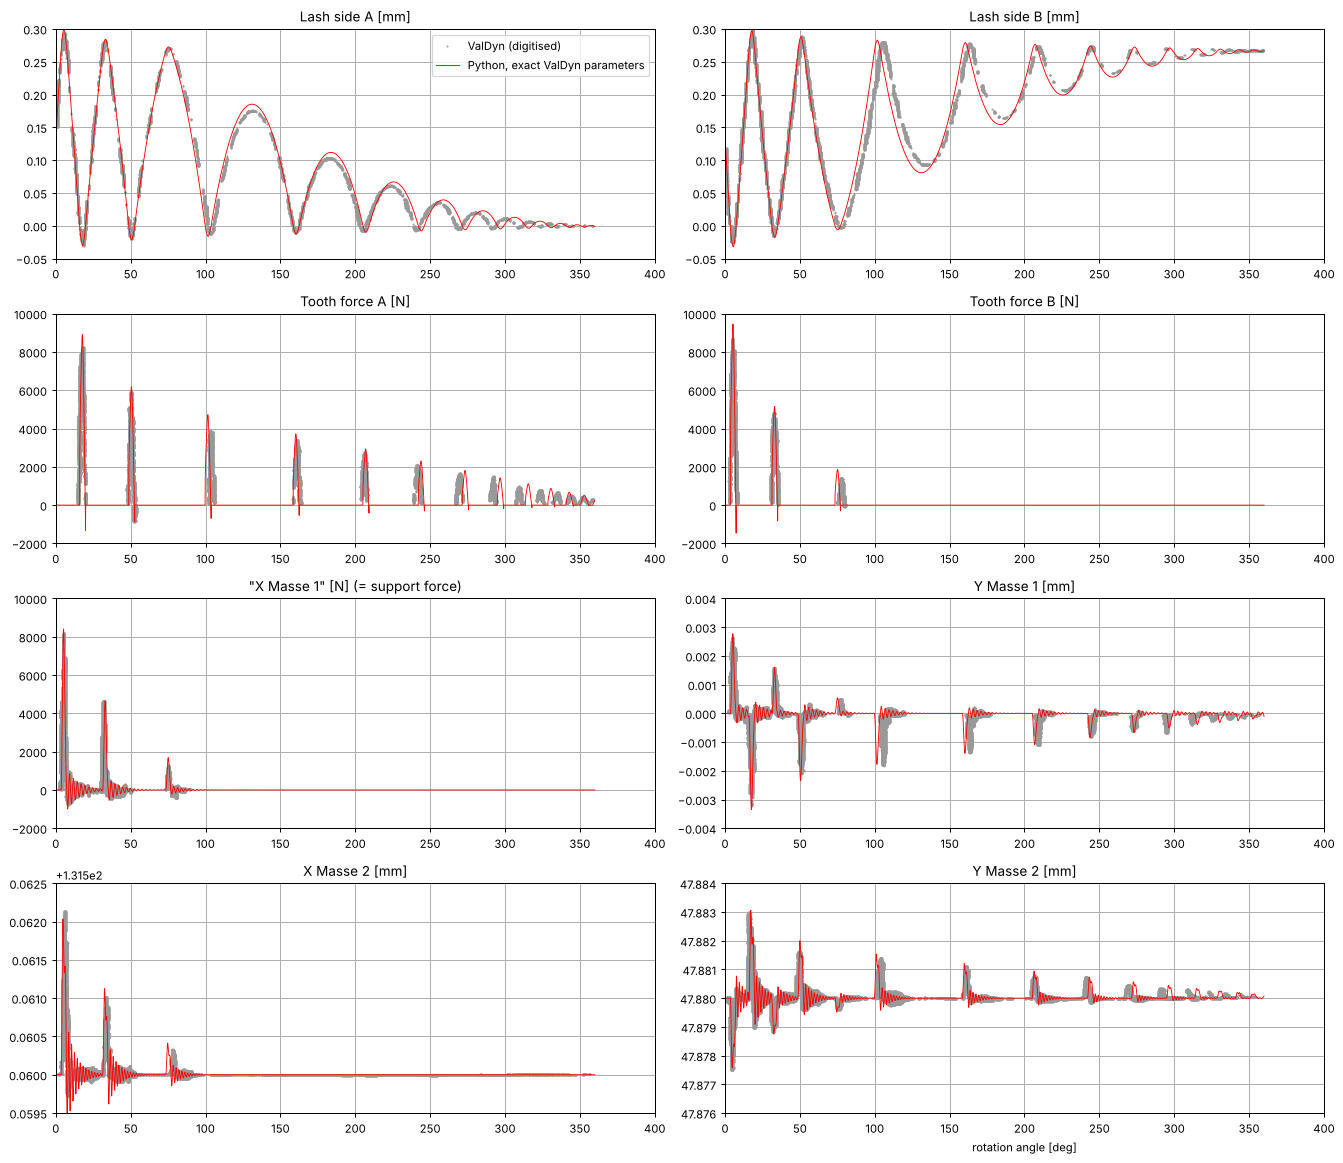

In [7]:
H = dict(hide_y0=0.012)
CH1 = [('s1_lashA_red', 'lashA', 1, 1), ('s1_lashB_red', 'lashB', 1, 1),
       ('s1_FA_green', 'FA', 1, 1, H), ('s1_FB_green', 'FB', 1, 1, H),
       ('s1_XM1_red', 'Fs1x', .3, -1, H),   # ValDyn plot "X Masse 1" in [N] = support force of gear 1 (sign: on gear)
       ('s1_YM1_green', 'y1', .3, 1), ('s1_XM2_red', 'x2', .3, 1), ('s1_YM2_green', 'y2', .3, 1)]
TITLES1 = {'s1_lashA_red': 'Lash side A [mm]', 's1_lashB_red': 'Lash side B [mm]', 's1_FA_green': 'Tooth force A [N]',
           's1_FB_green': 'Tooth force B [N]', 's1_XM1_red': '"X Masse 1" [N] (= support force)', 's1_YM1_green': 'Y Masse 1 [mm]',
           's1_XM2_red': 'X Masse 2 [mm]', 's1_YM2_green': 'Y Masse 2 [mm]'}

def compare1(runs, labels, colors=('r', 'b', 'g'), xlim=None):
    fig, axs = plt.subplots(4, 2, figsize=(15, 13)); axs = axs.ravel()
    for ax, c in zip(axs, CH1):
        R = REF[c[0]]; ax.plot(R.pts[:, 0], R.pts[:, 1], '.', ms=1.2, color='0.6', label='ValDyn (digitised)')
        for r, lab, col in zip(runs, labels, colors):
            ax.plot(r['angle'], c[3]*r[c[1]], col, lw=.7, label=lab)
        ax.set_xlim(xlim or R.xr); ax.set_ylim(R.yr); ax.set_title(TITLES1[c[0]])
    axs[0].legend(loc='upper right'); axs[-1].set_xlabel('rotation angle [deg]'); plt.tight_layout()

obj1 = ct.Objective(gm.simulate_stage1, gm.params(1), [], CH1, REF)
J0, d0 = obj1([], return_parts=True)
r_nom = gm.simulate_stage1(gm.params(1))
compare1([r_nom], ['Python, exact ValDyn parameters'])
print(f'J(nominal) = {J0:.3e}')
print('channel RMS distance (fraction of plot):', {k[3:]: round(v, 4) for k, v in d0.items()})

With the exact parameters the Python model already reproduces the ValDyn result: impact angles, bounce heights, decay, side-B → side-A transition and the support responses. Errors are around 0.4–1.5 % of the plot size, close to the digitisation floor.

Two observations from this step:
* The plot labelled **"X Masse 1" in [N]** is the **x support force of gear 1**, not a displacement. The Python support force (sign: force on the gear) matches it.
* Right after an impact the reference force curves show *two* traces about 1–2° apart (the legend lists `02500 gearpair2d1` twice). Peak heights are therefore more trustworthy than pulse widths.

## D.2 [M3] Structural hypotheses: which modelling decisions matter?
Each line changes **one** modelling decision and keeps all parameters at their ValDyn values.

In [8]:
variants = {
    'reference model (as above)': dict(),
    'damping clipped (F >= 0)': dict(clip_tension=True),
    'no initial over-speed (w2 = -40/30)': dict(w2_ratio=-40/30),
    'initial gap all on side A': dict(gap0_split=1.0),
    'flank directions swapped (alpha -> -alpha)': dict(alpha=-20.0),
}
rows = []
for name, kw in variants.items():
    J, d = ct.Objective(gm.simulate_stage1, gm.params(1, **kw), [], CH1, REF)([], return_parts=True)
    rows.append((name, J, d['s1_lashA_red'], d['s1_FB_green']))
# lash plotted as NORMAL backlash instead of pitch-circle value -> post-processing variant
r = gm.simulate_stage1(); rr = dict(r); rr['lashA'] = r['lashA']*np.cos(np.deg2rad(20)); rr['lashB'] = r['lashB']*np.cos(np.deg2rad(20))
dA = ct.curve_distance(REF['s1_lashA_red'], rr['angle'], rr['lashA']); dB = ct.curve_distance(REF['s1_lashB_red'], rr['angle'], rr['lashB'])
rows.append(('lash output = normal backlash (no 1/cos)', np.nan, dA, np.nan))
print('lash as normal backlash -> lashB distance %.4f vs %.4f (settles at 0.25 instead of 0.266 mm)' %
      (dB, ct.curve_distance(REF['s1_lashB_red'], r['angle'], r['lashB'])))
print(f'{"variant":45s} {"J":>10s} {"lashA":>8s} {"FB":>8s}')
for n, J, a, b in rows: print(f'{n:45s} {J:10.2e} {a:8.4f} {b:8.4f}')

lash as normal backlash -> lashB distance 0.0212 vs 0.0081 (settles at 0.25 instead of 0.266 mm)
variant                                                J    lashA       FB
reference model (as above)                      5.11e-04   0.0076   0.0152
damping clipped (F >= 0)                        1.61e-03   0.0190   0.0212
no initial over-speed (w2 = -40/30)             1.68e-01   0.1268   0.3257
initial gap all on side A                       1.53e-03   0.0140   0.0268
flank directions swapped (alpha -> -alpha)      2.71e-02   0.0076   0.0152
lash output = normal backlash (no 1/cos)             nan   0.0071      nan


Each "wrong" structural choice increases the error J by a factor of 3 to more than 300. The lash definition shows up mainly in the settled side-B value (0.25 vs 0.266 mm). **No parameter tuning can repair these**: an optimiser would only distort physical parameters to compensate. Rule: settle model form first, then parameters.

## D.3 [M4] Screening: Morris elementary effects
Ranges: ±40 % (log) for stiffness, damping and inertia, ±0.015 for the initial speed ratio, ±0.03 mm for the backlash. Each trajectory changes one parameter at a time, starting from random points in the box.

25 s


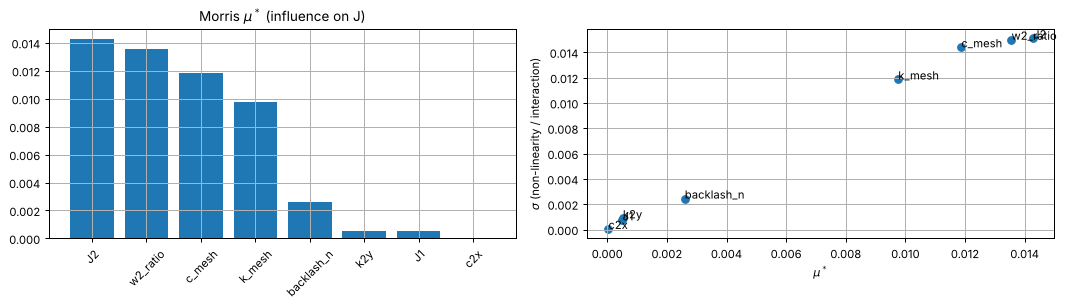

In [9]:
names_s = ['c_mesh', 'k_mesh', 'w2_ratio', 'backlash_n', 'J2', 'J1', 'c2x', 'k2y']
logs = {'c_mesh', 'k_mesh', 'J2', 'J1', 'c2x', 'k2y'}
objS = ct.Objective(gm.simulate_stage1, gm.params(1), names_s, CH1, REF, log=logs)
th0 = objS.theta0(); lo = th0.copy(); hi = th0.copy()
for i, n in enumerate(names_s):
    if n in logs: lo[i] -= 0.15; hi[i] += 0.15
lo[2], hi[2] = -1.385, -1.355; lo[3], hi[3] = 0.22, 0.28
t = time.time(); mu, sig, EE = ct.morris_screening(objS, lo, hi, r=10, seed=1); print(f'{time.time()-t:.0f} s')
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
o = np.argsort(mu)[::-1]
ax[0].bar(np.array(names_s)[o], mu[o]); ax[0].set_title('Morris $\\mu^*$ (influence on J)'); ax[0].tick_params(axis='x', rotation=45)
ax[1].scatter(mu, sig)
for n, a, b in zip(names_s, mu, sig): ax[1].annotate(n, (a, b))
ax[1].set_xlabel('$\\mu^*$'); ax[1].set_ylabel('$\\sigma$ (non-linearity / interaction)'); plt.tight_layout()

**Reading the screening:** mesh damping, mesh stiffness, the inertia J2, the initial over-speed and the backlash matter. J1, the support damping and the support stiffness of gear 2 are negligible: J1 is driven hard by the 4.3e7 N·m/rad spring, and the supports are 10× stiffer than the mesh. These drop out of the calibration.

σ is about as large as μ* for every important parameter, so the response is strongly non-linear. A bounce either does or does not happen; this is typical of impact problems.

## D.4 [M5] Local sensitivity and identifiability
Features: the angle and height of the first 8 side-A impacts and 3 side-B impacts (from the tooth-force curves). The Jacobian of these residuals, computed by finite differences, gives the linearised **parameter correlation**.

singular values of J: [1.971 1.553 0.406 0.163 0.023]  condition number: 86


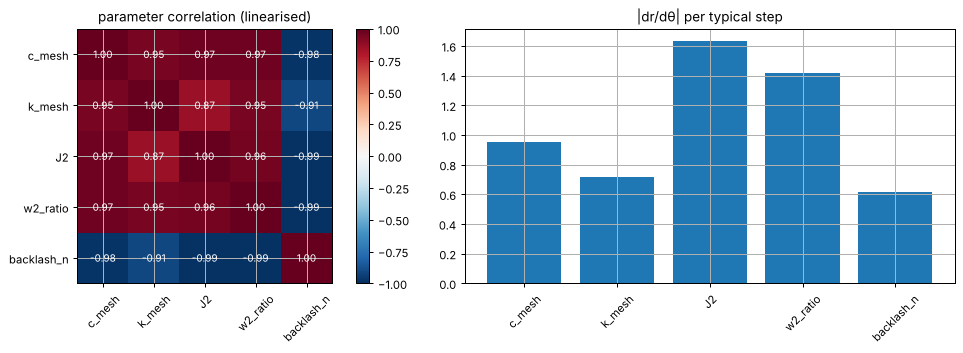

In [10]:
ev_ref = {k: ct.impact_events(REF[k].pts[:, 0], REF[k].pts[:, 1], 400, 4) for k in ('s1_FA_green', 's1_FB_green')}
def feat_res(theta, names, logs):
    p = gm.params(1)
    for n, v in zip(names, theta): p[n] = 10**v if n in logs else v
    r = gm.simulate_stage1(p)
    eA = ct.impact_events(r['angle'], r['FA'], 400, 4); eB = ct.impact_events(r['angle'], r['FB'], 400, 4)
    return np.r_[ct.event_residuals(eA, ev_ref['s1_FA_green'], 8), ct.event_residuals(eB, ev_ref['s1_FB_green'], 3)]

names_i = ['c_mesh', 'k_mesh', 'J2', 'w2_ratio', 'backlash_n']; logs_i = {'c_mesh', 'k_mesh', 'J2'}
th_i = np.array([np.log10(4300), np.log10(308000), np.log10(0.0054), -1.37, 0.25])
steps = np.array([0.02, 0.02, 0.02, 0.002, 0.005])
corr, sv, Jm = ct.jacobian_identifiability(lambda th: feat_res(th, names_i, logs_i), th_i, steps)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
im = ax[0].imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1); plt.colorbar(im, ax=ax[0])
ax[0].set_xticks(range(5)); ax[0].set_xticklabels(names_i, rotation=45); ax[0].set_yticks(range(5)); ax[0].set_yticklabels(names_i)
for i in range(5):
    for j in range(5): ax[0].text(j, i, f'{corr[i, j]:.2f}', ha='center', va='center', fontsize=8,
                                  color='w' if abs(corr[i, j]) > .5 else 'k')
ax[0].set_title('parameter correlation (linearised)')
ax[1].bar(names_i, np.linalg.norm(Jm, axis=0)); ax[1].set_title('|dr/dθ| per typical step'); ax[1].tick_params(axis='x', rotation=45)
plt.tight_layout(); print('singular values of J:', sv.round(3), ' condition number: %.0f' % (sv[0]/sv[-1]))

**Reading the matrix:** correlations near ±1 mean that the data cannot separate those parameters. With impact angles and peak heights as features, **all five** are strongly correlated (|ρ| ≈ 0.8–0.97, condition number about 90). They all act through the same physics, the impact energy (½·m_eq·v²), the contact frequency √(k/m_eq) and the energy loss per impact. Calibrating them together produces a fit that looks good but carries meaningless values.

Decision: **calibrate only k_mesh and c_mesh**, the genuinely uncertain contact parameters. Keep J2, the initial speed and the backlash at their mask values, which are known.

## D.5 [M6] 2-D sweep of the objective

Text(0.5, 1.0, 'objective landscape (stage 1)')

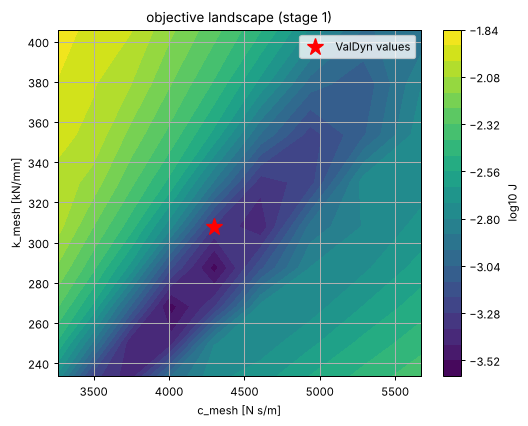

In [11]:
obj2 = ct.Objective(gm.simulate_stage1, gm.params(1), ['c_mesh', 'k_mesh'], CH1, REF, log={'c_mesh', 'k_mesh'})
cv = np.log10(4300) + np.linspace(-0.12, 0.12, 9); kv = np.log10(308000) + np.linspace(-0.12, 0.12, 9)
Z = ct.sweep_2d(obj2, obj2.theta0(), 0, cv, 1, kv)
fig, ax = plt.subplots(figsize=(6.5, 5))
cs = ax.contourf(10**cv, 10**kv/1e3, np.log10(Z), 20, cmap='viridis'); plt.colorbar(cs, label='log10 J')
ax.plot(4300, 308, 'r*', ms=14, label='ValDyn values'); ax.set_xlabel('c_mesh [N s/m]'); ax.set_ylabel('k_mesh [kN/mm]'); ax.legend()
ax.set_title('objective landscape (stage 1)')

The valley runs along a diagonal: stiffer mesh together with more damping gives a similar restitution. The ValDyn point sits inside the valley, close to its floor. The landscape is fairly smooth near the optimum but rough in places, where events appear or vanish. This is why a derivative-free optimiser is used below.

## D.6 [M7] Optimisation, with a weak prior towards the ValDyn values

In [12]:
results1 = {}
for subset in (['c_mesh', 'k_mesh'], ['c_mesh', 'k_mesh', 'w2_ratio', 'J2', 'backlash_n']):
    o = ct.Objective(gm.simulate_stage1, gm.params(1), subset, CH1, REF, log={'c_mesh', 'k_mesh', 'J2'},
                     prior_sigma={'c_mesh': .1, 'k_mesh': .1, 'J2': .05, 'w2_ratio': .01, 'backlash_n': .01})
    t = time.time()
    r = minimize(o, o.theta0(), method='Nelder-Mead', options=dict(xatol=1e-4, fatol=1e-7, maxfev=300))
    p = o.to_params(r.x); J, d = o(r.x, return_parts=True)
    results1[len(subset)] = (p, J, d)
    print(f'{len(subset)} parameters: J = {J:.3e} ({r.nfev} runs, {time.time()-t:.0f} s)  ->',
          {n: (round(p[n], 5) if abs(p[n]) < 10 else round(p[n])) for n in subset})
print(f'nominal:      J = {J0:.3e}')

2 parameters: J = 2.695e-04 (86 runs, 18 s)  -> {'c_mesh': 4216, 'k_mesh': 282188}


5 parameters: J = 2.418e-04 (248 runs, 51 s)  -> {'c_mesh': 4235, 'k_mesh': 313609, 'w2_ratio': np.float64(-1.36856), 'J2': np.float64(0.00517), 'backlash_n': np.float64(0.24933)}
nominal:      J = 5.108e-04


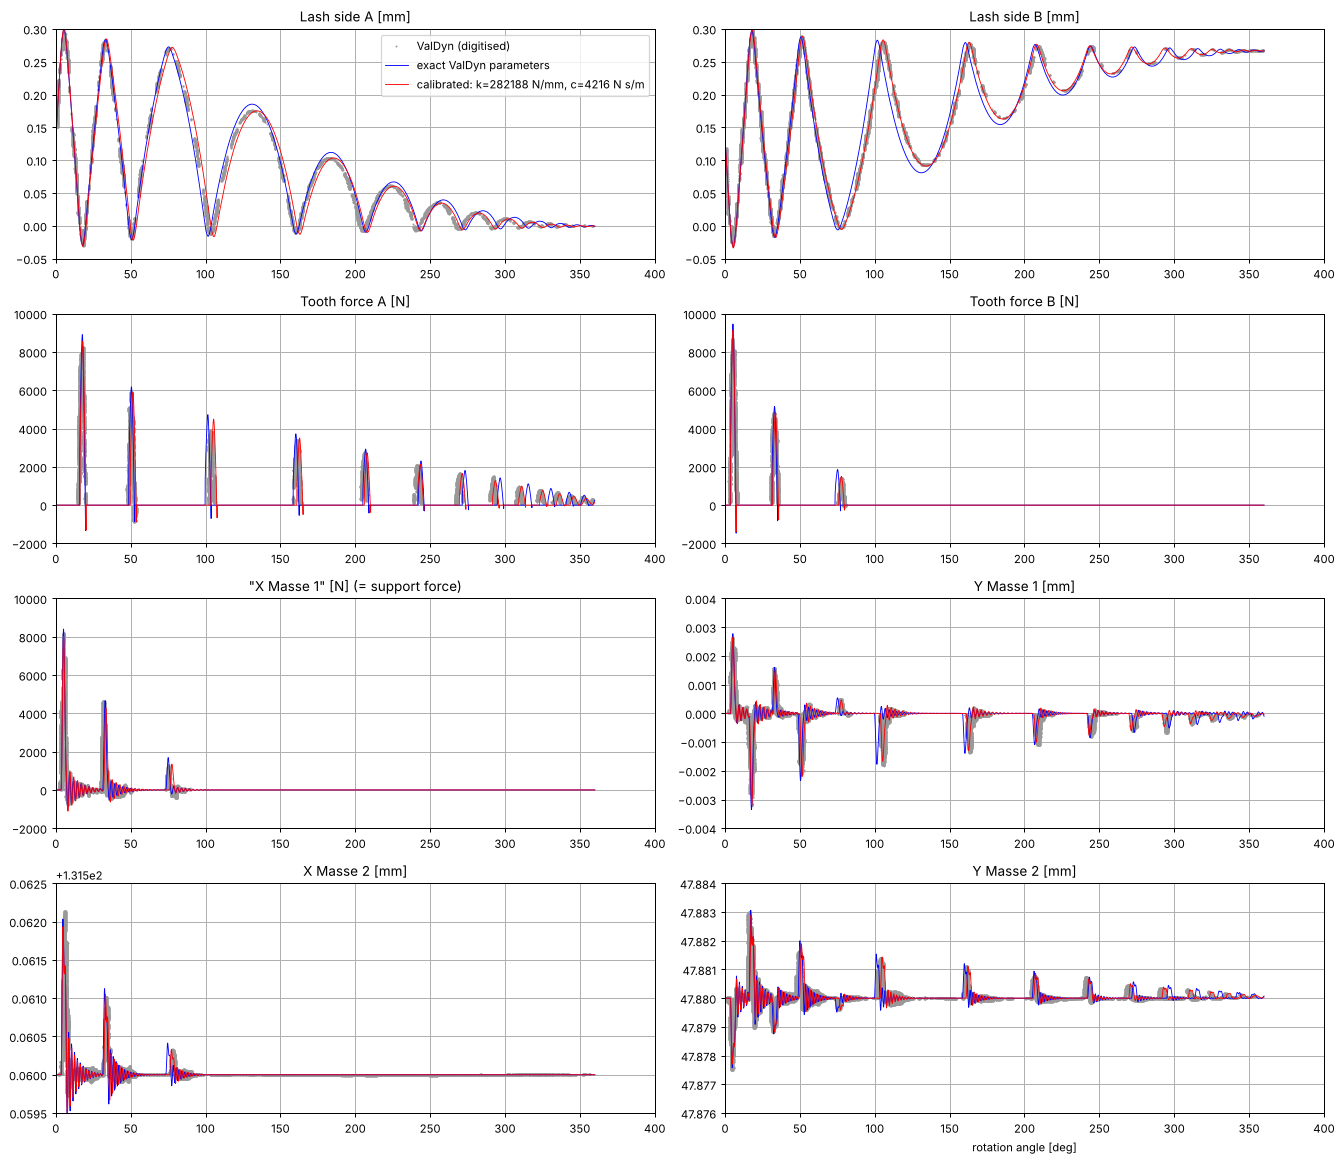

In [13]:
p_cal1 = results1[2][0]
r_cal1 = gm.simulate_stage1(p_cal1)
compare1([r_nom, r_cal1], ['exact ValDyn parameters', f'calibrated: k={p_cal1["k_mesh"]:.0f} N/mm, c={p_cal1["c_mesh"]:.0f} N s/m'],
         colors=('b', 'r'))

## D.7 [M8] Assessment, stage 1
* The **two-parameter calibration** roughly halves J: k_mesh ≈ −8 %, c_mesh ≈ −2 %. The remaining errors are at the digitisation floor.
* The **five-parameter** fit brings almost nothing more. Its values move along the correlated directions found in D.4 (J2 down, k up), the classic signature of over-parameterisation. It is rejected.
* The change of k_mesh is small enough that it can be explained by **how the data were produced**: peaks of short pulses drawn as polylines at the ValDyn output step, and a photo. **Recommendation: use the original ValDyn parameters for stage 1.** The model is verified.

# Part E: Stage 2, gear on a shaft with bearing clearance
## E.1 [M1] Baseline with the exact parameters
Mapping between ValDyn outputs and model quantities (settled in E.5):
`BearingX` → gear-2 centre x · `BearingY` → shaft node under the bearing, y · Block/Case X/Y → shaft-end nodes · `FXBlock`… → support force **acting on the shaft**.

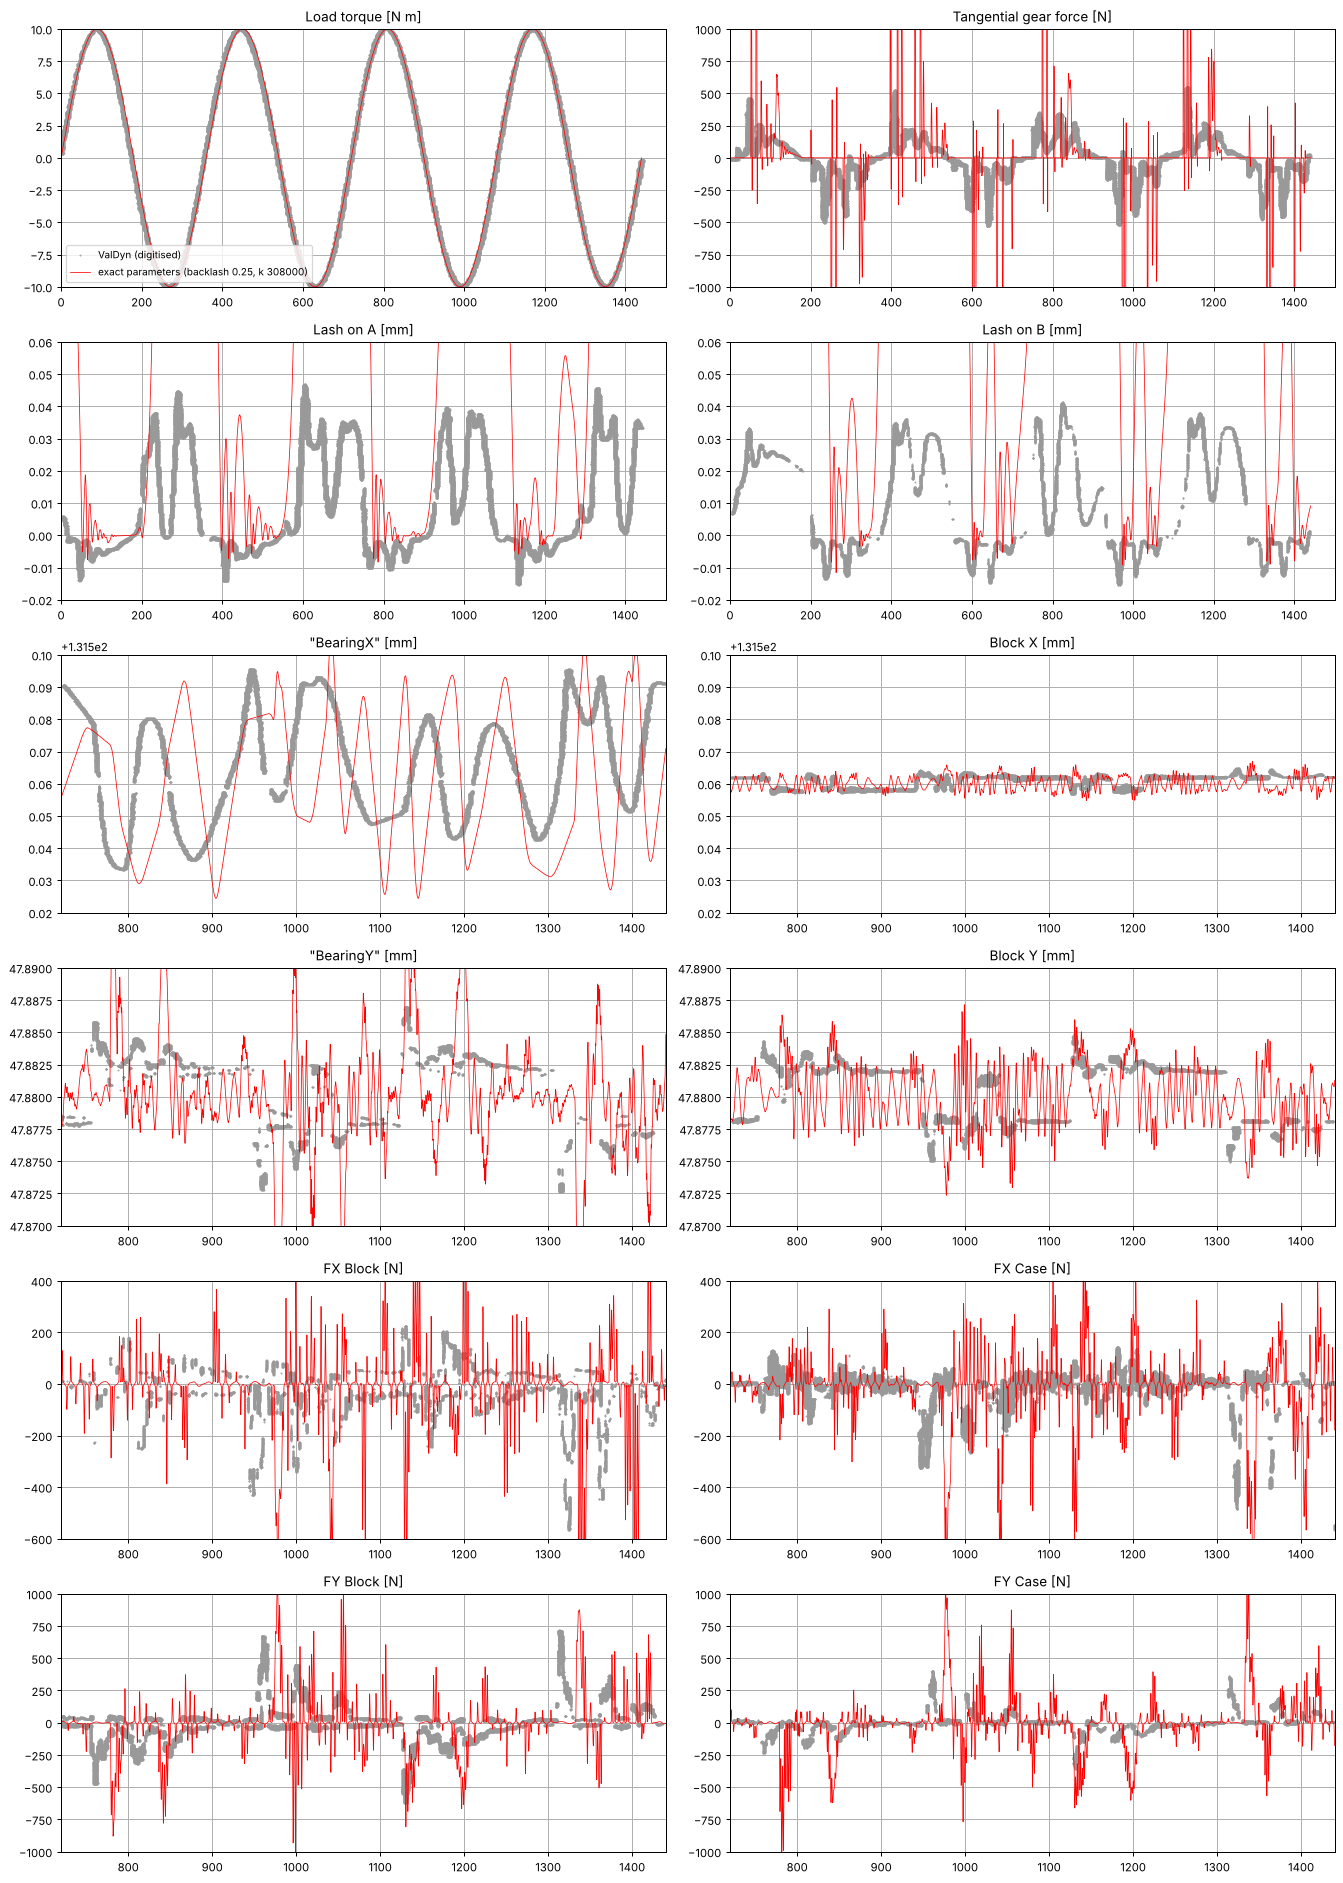

In [14]:
CH2 = [('s2_T_red', 'Tload', 1), ('s2_Ft_red', 'Ft', 1), ('s2_lash_red', 'lashA', 1), ('s2_lash_blue', 'lashB', 1),
       ('s2_X_red', 'gearX', 1), ('s2_X_cyan', 'blockX', 1), ('s2_Y_red', 'midY', 1), ('s2_Y_cyan', 'blockY', 1),
       ('s2_FX_red', 'FXBlock', -1), ('s2_FX_blue', 'FXCase', -1), ('s2_FY_red', 'FYBlock', -1), ('s2_FY_blue', 'FYCase', -1)]
TITLES2 = {'s2_T_red': 'Load torque [N m]', 's2_Ft_red': 'Tangential gear force [N]', 's2_lash_red': 'Lash on A [mm]',
           's2_lash_blue': 'Lash on B [mm]', 's2_X_red': '"BearingX" [mm]', 's2_X_cyan': 'Block X [mm]',
           's2_Y_red': '"BearingY" [mm]', 's2_Y_cyan': 'Block Y [mm]', 's2_FX_red': 'FX Block [N]',
           's2_FX_blue': 'FX Case [N]', 's2_FY_red': 'FY Block [N]', 's2_FY_blue': 'FY Case [N]'}
def compare2(runs, labels, colors=('r', 'b')):
    fig, axs = plt.subplots(6, 2, figsize=(15, 21)); axs = axs.ravel()
    for ax, (rk, sk, sg) in zip(axs, CH2):
        R = REF[rk]; ax.plot(R.pts[:, 0], R.pts[:, 1], '.', ms=1, color='0.6', label='ValDyn (digitised)')
        for r, lab, col in zip(runs, labels, colors): ax.plot(r['angle'], sg*r[sk], col, lw=.6, label=lab)
        ax.set_xlim(R.xr); ax.set_ylim(R.yr); ax.set_title(TITLES2[rk])
    axs[0].legend(loc='lower left', fontsize=8); plt.tight_layout()

p2_nom = gm.params(2)
r2_nom = gm.simulate_stage2(p2_nom)
compare2([r2_nom], ['exact parameters (backlash 0.25, k 308000)'])

With the mask values (normal backlash 0.25 mm), the reference **cannot** be reproduced. The lash plot shows the gear rattling over a ±0.13 mm play, while ValDyn never exceeds about 0.045 mm in total lash. The torque input agrees exactly, which confirms the load definition and the angle axis.

## E.2 [M2] Is the response deterministic? Chaos check
Repeat the run with gear mass m₂·(1 + 10⁻⁶), and separately with half the time step. How quickly do the trajectories diverge?

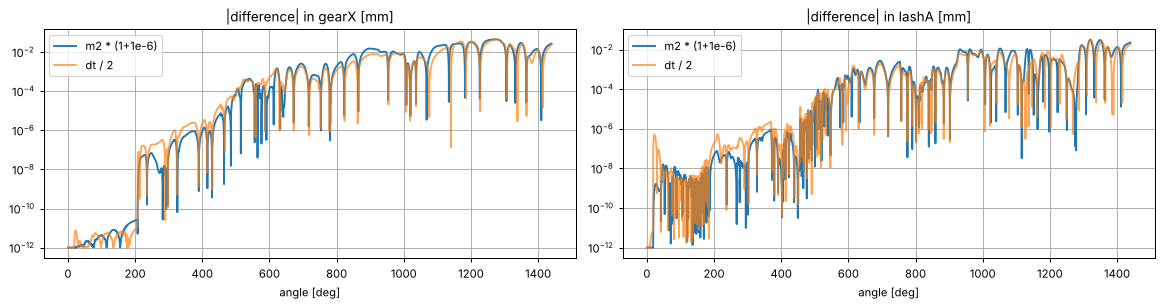

In [15]:
pp = gm.params(2, backlash_n=0.012, k_mesh=25000)
a = gm.simulate_stage2(pp); b = gm.simulate_stage2(dict(pp, m2=pp['m2']*(1+1e-6))); c = gm.simulate_stage2(pp, dt=1e-7)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
for s, axx in zip(['gearX', 'lashA'], ax):
    axx.semilogy(a['angle'], np.abs(a[s]-b[s])+1e-12, label='m2 * (1+1e-6)')
    axx.semilogy(a['angle'], np.abs(a[s]-c[s][:len(a[s])])+1e-12, label='dt / 2', alpha=.7)
    axx.set_title(f'|difference| in {s} [mm]'); axx.set_xlabel('angle [deg]'); axx.legend()
plt.tight_layout()

A relative perturbation of 10⁻⁶, or a different time step, grows exponentially. After a few hundred degrees the two runs are no longer the same trajectory. This is **sensitive dependence on initial conditions**, which is typical of rattling in clearance and backlash. ValDyn's own result would change in the same way with a different solver tolerance.

Consequences for the metric (**[M2]**):
1. **Deterministic window** (0–200°): compare trajectories directly with the Chamfer distance.
2. **Whole horizon:** compare **statistics**. Here these are phase-windowed envelopes: the mean upper and lower envelope in 45° windows, which are reproducible.
3. Average the model statistics over a small **ensemble** (3 runs with 10⁻⁶ perturbations). The objective remains slightly **noisy** (std ≈ 0.002–0.006), which matters for the optimiser in E.6.

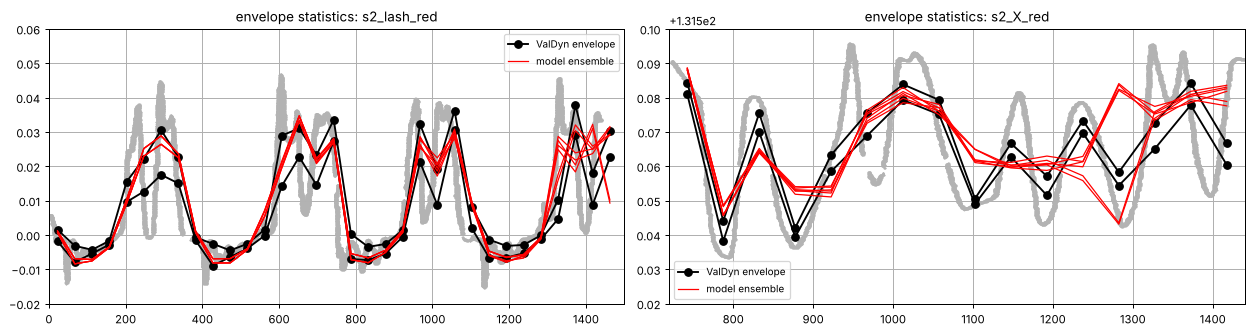

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(14, 3.8))
runs = so.run_ensemble(pp, n=3)
for ax, (rk, sk) in zip(axs, [('s2_lash_red', 'lashA'), ('s2_X_red', 'gearX')]):
    R = REF[rk]; e = ct.envelope_stats(R.pts[:, 0], R.pts[:, 1], R.xr, 2, 45, True); n = len(e)//2
    xc = R.xr[0] + 45*(np.arange(n)+.5)
    ax.plot(R.pts[:, 0], R.pts[:, 1], '.', ms=1, color='.7'); ax.plot(xc, e[:n], 'k-o', label='ValDyn envelope'); ax.plot(xc, e[n:], 'k-o')
    for i, r in enumerate(runs):
        s = ct.envelope_stats(r['angle'], r[sk], R.xr, 2, 45)
        ax.plot(xc, s[:n], 'r-', lw=1, label='model ensemble' if i == 0 else None); ax.plot(xc, s[n:], 'r-', lw=1)
    ax.set_xlim(R.xr); ax.set_ylim(R.yr); ax.set_title('envelope statistics: ' + rk); ax.legend(fontsize=8)
plt.tight_layout()

## E.3 [M6] 1-D sweep of the obvious suspect: backlash

{0.25: np.float64(0.8239), 0.1: np.float64(0.5483), 0.05: np.float64(0.2949), 0.03: np.float64(0.0885), 0.02: np.float64(0.0402), 0.012: np.float64(0.036), 0.008: np.float64(0.0464)}


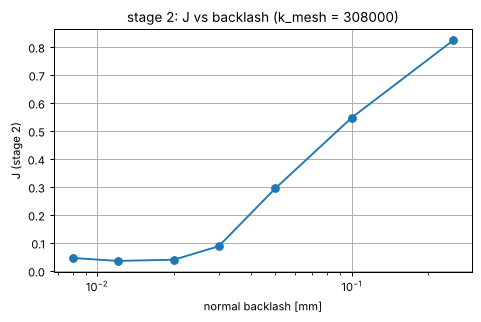

In [17]:
bl = [0.25, 0.1, 0.05, 0.03, 0.02, 0.012, 0.008]
Jb = [so.evaluate(gm.params(2, backlash_n=b), REF, n=2) for b in bl]
plt.figure(figsize=(6, 3.5)); plt.semilogx(bl, Jb, 'o-'); plt.xlabel('normal backlash [mm]'); plt.ylabel('J (stage 2)')
plt.title('stage 2: J vs backlash (k_mesh = 308000)'); print(dict(zip(bl, np.round(Jb, 4))))

The error falls by more than an order of magnitude once the backlash is reduced to a few hundredths of a millimetre.

## E.4 [M0] Hand estimate of the mesh stiffness from the reference data
During contact phases, ValDyn's lash is clearly **negative**, about −0.005 to −0.012 mm. That is the tooth deflection. With k = 308 000 N/mm and only about 200 N of tooth force, the deflection would be about 0.0007 mm, more than 10× smaller than what ValDyn shows. Fitting lash against tangential force during contact (lash = −F_t/(k·cos²α)) estimates k directly from the data:

Text(0.5, 1.0, 'compliance read from ValDyn plots')

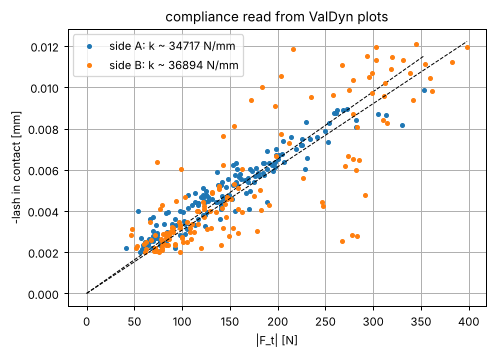

In [18]:
def binmed(P, edges):
    i = np.digitize(P[:, 0], edges)-1
    return np.array([np.median(P[i == k, 1]) if np.sum(i == k) > 2 else np.nan for k in range(len(edges)-1)])
e = np.arange(0, 1441, 3.0)
LA, LB, Ft = binmed(REF['s2_lash_red'].pts, e), binmed(REF['s2_lash_blue'].pts, e), binmed(REF['s2_Ft_red'].pts, e)
ca2 = np.cos(np.deg2rad(20))**2
fig, ax = plt.subplots(figsize=(6, 4))
for L, sgn, lab in [(LA, 1, 'side A'), (LB, -1, 'side B')]:
    m = (L < -0.002) & (sgn*Ft > 40); x, y = sgn*Ft[m], -L[m]
    slope = np.sum(x*y)/np.sum(x*x); ax.plot(x, y, '.', label=f'{lab}: k ~ {1/(slope*ca2):.0f} N/mm')
    xx = np.linspace(0, x.max(), 10); ax.plot(xx, slope*xx, 'k--', lw=.8)
ax.set_xlabel('|F_t| [N]'); ax.set_ylabel('-lash in contact [mm]'); ax.legend(); ax.set_title('compliance read from ValDyn plots')

The data alone give **k_mesh ≈ 35 000 N/mm**, the right order of magnitude, about 9× lower than in the mask. An estimate like this is a strong prior for the next step, and it is cheap.

## E.5 [M6]+[M3] 2-D grid (k_mesh × backlash) and structural hypotheses
The objective is noisy, so a grid with averaging over two ensembles is more robust than a local optimiser.

grid: 83 s
best grid point: k_mesh=25000 N/mm, backlash=0.012 mm, J=0.0214; at k=308000: min J=0.0368


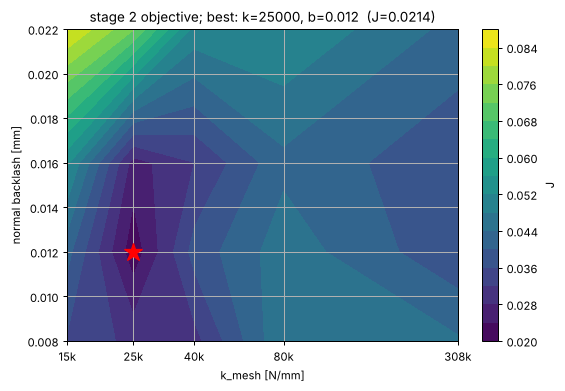

In [19]:
def J2avg(kw, seeds=(0, 1), n=3):
    orig = so.run_ensemble
    Js = []
    for sd in seeds:
        runs = orig(dict(gm.params(2, **kw), m2=1.5*(1+3e-6*sd)), n)
        parts = {}
        for rk, sk, w, sg in so.DET_CHANNELS:
            parts['det:'+rk] = ct.curve_distance(REF[rk], runs[0]['angle'], sg*runs[0][sk], so.DET_WINDOW)
        for rk, sk, w, sg in so.STAT_CHANNELS:
            parts['stat:'+rk] = ct.stat_distance(REF[rk], [(r['angle'], sg*r[sk]) for r in runs])
        Js.append(sum(w*parts['det:'+rk]**2 for rk, sk, w, sg in so.DET_CHANNELS) +
                  sum(w*parts['stat:'+rk]**2 for rk, sk, w, sg in so.STAT_CHANNELS))
    return float(np.mean(Js)), float(np.std(Js))

t = time.time()
kgrid = [15000, 25000, 40000, 80000, 308000]; bgrid = [0.008, 0.012, 0.016, 0.022]
JG = np.array([[J2avg(dict(k_mesh=k, backlash_n=b))[0] for k in kgrid] for b in bgrid])
print(f'grid: {time.time()-t:.0f} s')
fig, ax = plt.subplots(figsize=(7, 4.5))
cs = ax.contourf(np.log10(kgrid), bgrid, JG, 20, cmap='viridis'); plt.colorbar(cs, label='J')
ax.set_xticks(np.log10(kgrid)); ax.set_xticklabels([f'{k/1e3:g}k' for k in kgrid]); ax.set_xlabel('k_mesh [N/mm]'); ax.set_ylabel('normal backlash [mm]')
i, j = np.unravel_index(np.argmin(JG), JG.shape); ax.plot(np.log10(kgrid[j]), bgrid[i], 'r*', ms=15)
ax.set_title(f'stage 2 objective; best: k={kgrid[j]}, b={bgrid[i]}  (J={JG[i, j]:.4f})')
print(f'best grid point: k_mesh={kgrid[j]} N/mm, backlash={bgrid[i]} mm, J={JG[i, j]:.4f}; at k=308000: min J={JG[:, -1].min():.4f}')

In [20]:
# [M3] discrete structural hypotheses, evaluated at the best (k, b)
best = dict(k_mesh=25000, backlash_n=0.012)
hyp = {
    'best (3000 rpm, circular clearance 30 um radius)': {},
    'speed 2500 rpm (slide text)':                      dict(speed_rpm=2500),
    'clearance 30 um is diametral (15 um radius)':     dict(clr_is_diametral=True),
    'clearance per plane (box)':                       dict(clr_mode='per_plane'),
    'support damping column in N s/mm (x1000)':        dict(damp_scale=1000),
    'initial over-speed -1.37 as in stage 1':          dict(w2_ratio=-1.37),
    'mesh stiffness 30800 (factor-10 typo?)':          dict(k_mesh=30800),
}
for name, kw in hyp.items():
    m, s = J2avg(dict(best, **kw)); print(f'{name:50s} J = {m:.4f} +- {s:.4f}')

best (3000 rpm, circular clearance 30 um radius)   J = 0.0214 +- 0.0003


speed 2500 rpm (slide text)                        J = 0.0379 +- 0.0016


clearance 30 um is diametral (15 um radius)        J = 0.0252 +- 0.0000


clearance per plane (box)                          J = 0.0532 +- 0.0021


support damping column in N s/mm (x1000)           J = 0.0337 +- 0.0000


initial over-speed -1.37 as in stage 1             J = 0.1019 +- 0.0029


mesh stiffness 30800 (factor-10 typo?)             J = 0.0300 +- 0.0070


In [21]:
# [M3] output interpretation: which model quantity matches ValDyn's "BearingX/Y" and which force sign is used?
r = gm.simulate_stage2(gm.params(2, **best))
for rk, cands in [('s2_X_red', ['gearX', 'midX']), ('s2_Y_red', ['midY', 'gearY'])]:
    print(rk, {c: round(ct.curve_distance(REF[rk], r['angle'], r[c]), 4) for c in cands})
for rk, sk in [('s2_FX_red', 'FXBlock'), ('s2_FY_red', 'FYBlock')]:
    print(rk, {f'sign {sg:+d}': round(ct.curve_distance(REF[rk], r['angle'], sg*r[sk], hide_y0=0.012), 4) for sg in (1, -1)})

s2_X_red {'gearX': 0.0314, 'midX': 0.1094}
s2_Y_red {'midY': 0.0398, 'gearY': 0.1786}
s2_FX_red {'sign +1': 0.0975, 'sign -1': 0.0282}


s2_FY_red {'sign +1': 0.0844, 'sign -1': 0.0193}


**Findings**
* **Speed:** 3000 rpm fits better than 2500 rpm. The result files are labelled `03000`, so the slide text "still 2500 rpm" is probably outdated.
* **Clearance:** radial vs diametral (30 vs 15 µm) cannot be distinguished within the objective noise. Under per-plane (box) clearance the gear would float ±30 µm in *Y* as well, which ValDyn does not show.
* **Support-damping units:** N·s/mm (×1000) is worse. The table values are N·s/m.
* **Initial speed:** the stage-1 over-speed (−1.37) makes the fit much worse. Stage 2 starts at the kinematic ratio −40/30.
* **The 30 800 N/mm variant** (a factor-10 typo) is close to the optimum and within about 1–2 σ of the noise. Only the original ValDyn file can settle this.
* **Output mapping:** ValDyn's `BearingX` behaves like the **gear centre**, but `BearingY` behaves like the **shaft node** under the bearing. In the model the gear jumps ±30 µm in y when the flank side changes, which is not visible in ValDyn's `BearingY`. Either the plot uses different nodes for X and Y, or the R_BEARING clearance acts differently in Y. **Open question for the colleague.**
* **Force sign:** ValDyn's `FXBlock` etc. are the forces *acting on the shaft*.

## E.6 [M7] Local optimiser on a noisy objective (and why to be careful)

33 s; NM end point k=25000, b=0.0120, J=0.0228


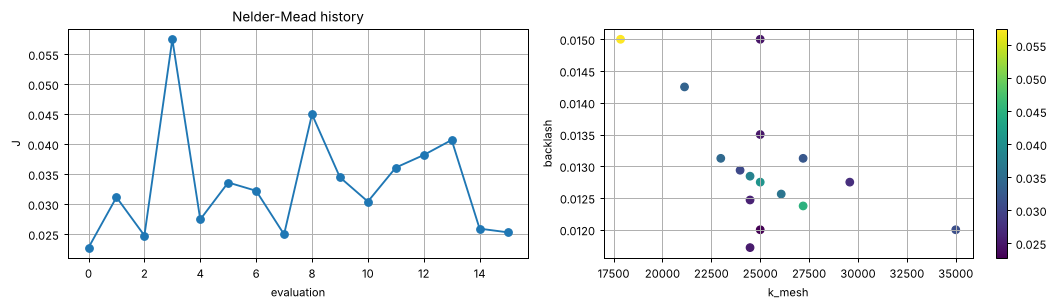

In [22]:
hist = []
def Jopt(th):
    v = J2avg(dict(k_mesh=10**th[0], backlash_n=th[1]), seeds=(0,))[0]; hist.append((10**th[0], th[1], v)); return v
t = time.time()
r = minimize(Jopt, [np.log10(25000), 0.012], method='Nelder-Mead',
             options=dict(initial_simplex=[[np.log10(25000), .012], [np.log10(35000), .012], [np.log10(25000), .015]], maxfev=16))
h = np.array(hist); print(f'{time.time()-t:.0f} s; NM end point k={10**r.x[0]:.0f}, b={r.x[1]:.4f}, J={r.fun:.4f}')
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(h[:, 2], 'o-'); ax[0].set_xlabel('evaluation'); ax[0].set_ylabel('J'); ax[0].set_title('Nelder-Mead history')
sc = ax[1].scatter(h[:, 0], h[:, 1], c=h[:, 2], cmap='viridis'); plt.colorbar(sc); ax[1].set_xlabel('k_mesh'); ax[1].set_ylabel('backlash')
plt.tight_layout()

Nelder–Mead quickly contracts into a region about the size of the noise, then "optimises noise": nearly identical points give J values that differ by ±20 %. On a noisy objective, **stop when the step size reaches the noise level**. The results are then a *region* (k ≈ 22 000–31 000 N/mm, b ≈ 0.011–0.013 mm) rather than a point. To refine further, use more ensemble members, a surrogate or response-surface fit to the grid, or Bayesian optimisation.

## E.7 Final comparison, stage 2

J exact params: 0.808 | backlash only: 0.0368 | backlash + k_mesh: 0.0214 +- 0.0003


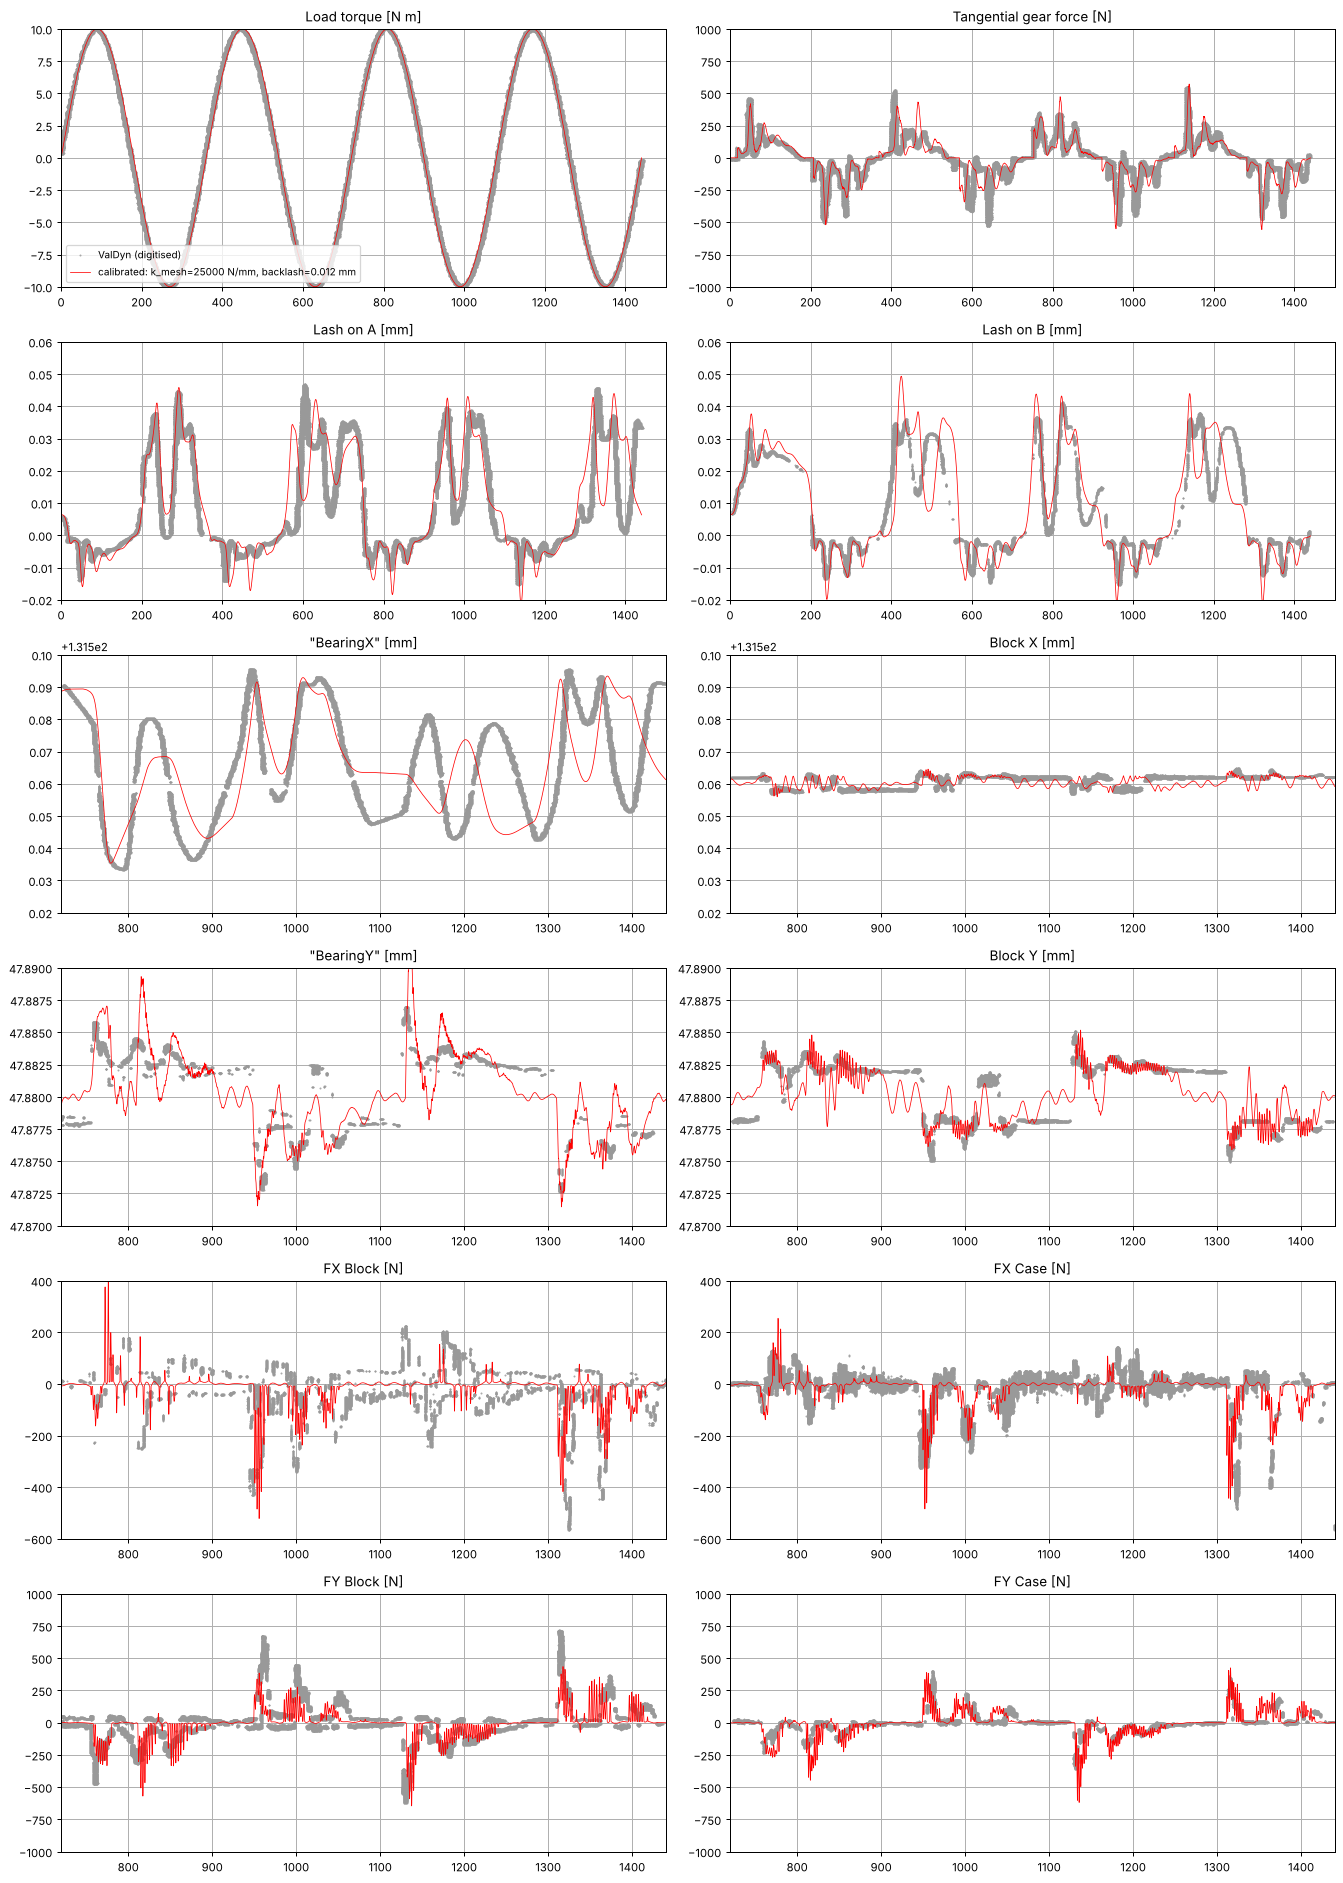

In [23]:
p2_cal = gm.params(2, k_mesh=25000, backlash_n=0.012)
r2_cal = gm.simulate_stage2(p2_cal)
compare2([r2_cal], ['calibrated: k_mesh=25000 N/mm, backlash=0.012 mm'])
Jn = J2avg(dict()); Jc = J2avg(dict(k_mesh=25000, backlash_n=0.012)); Jb = J2avg(dict(backlash_n=0.012))
print(f'J exact params: {Jn[0]:.3f} | backlash only: {Jb[0]:.4f} | backlash + k_mesh: {Jc[0]:.4f} +- {Jc[1]:.4f}')

With only two parameters changed, the calibrated model reproduces:
* lash A and lash B, including the **negative lash during contact** (tooth deflection);
* the tangential force with its impacts;
* the large swings of the gear inside the 30 µm bearing clearance (around 790°, 950°, 1030° and 1330°);
* the ±2.5 µm plateaus of the shaft ends;
* the Block/Case X/Y force peaks at the correct angles (about 950°, 1130° and 1310°).

Where the curves diverge later, this is expected for a chaotic response (E.2).

# Part F: Summary, open questions, next steps

**Stage 1** is verified. The Python model and ValDyn agree with the original parameters. The modelling details that decide the match:

| Detail | Correct choice |
|---|---|
| Lash output | Pitch circle: lash = −δ/cos α |
| Damping | Not clipped |
| Initial gap | Centred |
| Initial speed | −1.37 (gives the start-up impacts) |
| Flank geometry | Side A vertical |

**Stage 2** needs **normal backlash ≈ 0.012 mm** (instead of 0.25 mm) and **k_mesh ≈ 25 000 N/mm** (range about 22–31k, instead of 308 000), at **3000 rpm**, starting without over-speed. This cuts the stage-2 objective from about 0.81 (exact parameters) to about 0.021. Fixing the backlash alone gives about 0.037.

### Questions for the colleague (ask before calibrating any further)
1. Stage 2: were backlash and tooth stiffness different from the stage-1 mask (for example 0.0125 mm and 30 800 N/mm)? Can you get the original `.vdn` or the input deck?
2. Stage 2 speed: 2500 or 3000 rpm? The plots are labelled `03000`.
3. Which nodes are plotted as `BearingX` and `BearingY`, and how is the R_BEARING "radial clearance" defined: radius or diametral, circular or per plane?
4. MASS_8 mass formula: is `/2*pi/4` missing on purpose?
5. Units of the third column in the Block/Case tables (assumed N·s/m)?
6. ValDyn output step size, which determines how far the force peaks are under-sampled.

### General procedure (cheat sheet)
`M0 audit → M1 baseline (exact values) → M2 metric + noise floor → M3 model-form hypotheses → M4 screening → M5 identifiability → M6 sweeps → M7 optimise few parameters (with prior) → M8 judge against noise floor and physics`

* If the baseline is far off, look for **model-form or input errors first**: units, output definitions, sign conventions. Parameter tuning comes last.
* Hand estimates (impact force, compliance from lash vs force) often get you within a factor of 2 before any optimiser runs.
* Every extra parameter has to earn its place against the noise floor. Watch for correlated parameter pairs.
* For impacts, clearances and other chaotic systems, compare **statistics** over a deterministic window and use ensembles. Do not over-optimise a noisy objective.